# 01 · Text Is Not Characters

> **The reframe.** A model does not receive your letters or your words. It
> receives *tokens* — chunks of characters a tokenizer learned from a corpus.
> Whatever the tokenizer hides, the model cannot see.

In this notebook we look at one short string three ways — as characters, as
bytes, and as the tokens a real tokenizer produces — and establish the central
fact of the whole project. Then we introduce **tokens-per-character**, the
compression view that connects tokenization to information theory.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## Three ways to look at one string

In [2]:
from src.datasets.corpora import parallel_sentences, training_corpus
from src.reference.compare import try_get_reference_encoding

sample = "I would like a cup of coffee."

# Prefer a real production tokenizer (GPT-2 via tiktoken); fall back to the
# from-scratch BPE if we are offline, so the notebook always runs.
enc = try_get_reference_encoding("gpt2")
if enc is not None:
    tokenizer_name = "tiktoken:gpt2"
    token_ids = enc.encode(sample)
    pieces = [enc.decode([t]) for t in token_ids]
else:
    from src.bpe import BPETokenizer

    tokenizer_name = "from-scratch-bpe"
    _tok = BPETokenizer().train(training_corpus(40_000), vocab_size=512)
    token_ids = _tok.encode(sample)
    pieces = _tok.pieces(sample)

chars = list(sample)
byts = list(sample.encode("utf-8"))

print("tokenizer:", tokenizer_name)
print(f"characters ({len(chars)}):", chars)
print(f"bytes ({len(byts)}):", byts)
print(f"tokens ({len(token_ids)}):", pieces)

tokenizer: tiktoken:gpt2
characters (29): ['I', ' ', 'w', 'o', 'u', 'l', 'd', ' ', 'l', 'i', 'k', 'e', ' ', 'a', ' ', 'c', 'u', 'p', ' ', 'o', 'f', ' ', 'c', 'o', 'f', 'f', 'e', 'e', '.']
bytes (29): [73, 32, 119, 111, 117, 108, 100, 32, 108, 105, 107, 101, 32, 97, 32, 99, 117, 112, 32, 111, 102, 32, 99, 111, 102, 102, 101, 101, 46]
tokens (8): ['I', ' would', ' like', ' a', ' cup', ' of', ' coffee', '.']


The model never sees the top row (letters) or the middle row (bytes). It sees
the **bottom row**: a short sequence of tokens. Counting characters, reversing a
word, or reading a digit means reaching *inside* a token — which the model
cannot do.

In [3]:
representations = {
    "text": sample,
    "tokenizer": tokenizer_name,
    "characters": chars,
    "num_characters": len(chars),
    "bytes": byts,
    "num_bytes": len(byts),
    "token_ids": token_ids,
    "token_pieces": pieces,
    "num_tokens": len(token_ids),
}
print("saved:", save_json("01_representations", representations))

saved: /workspaces/tokenization_101/outputs/data/01_representations.json


## The compression view: tokens per character

saved: /workspaces/tokenization_101/outputs/data/01_compression.json
saved: /workspaces/tokenization_101/outputs/figures/01_compression.png


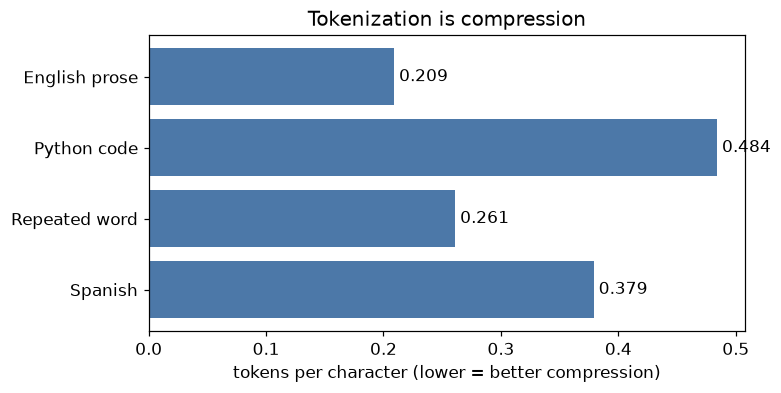

In [4]:
def tok_count(text):
    return len(enc.encode(text)) if enc is not None else len(_tok.encode(text))

samples = {
    "English prose": "the quick brown fox jumps over the lazy dog",
    "Python code": "def add(a, b):\n    return a + b",
    "Repeated word": "the the the the the the",
    "Spanish": parallel_sentences()["Spanish"],
}

rows = []
for label, text in samples.items():
    n = tok_count(text)
    rows.append(
        {
            "label": label,
            "chars": len(text),
            "tokens": n,
            "tokens_per_char": round(n / len(text), 3),
        }
    )
print("saved:", save_json("01_compression", rows))

labels = [r["label"] for r in rows]
values = [r["tokens_per_char"] for r in rows]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(labels, values, color="#4C78A8")
ax.invert_yaxis()
ax.set_xlabel("tokens per character (lower = better compression)")
ax.set_title("Tokenization is compression")
for y, v in enumerate(values):
    ax.text(v, y, f" {v}", va="center")
print("saved:", save_figure(fig, "01_compression"))
plt.show()

**Takeaway.** Tokenization is a lossy-*to-the-model* abstraction layer applied
before anything else. Fewer tokens per character means better compression — a
compression idea we build from scratch in the next notebook, and the exact lens
behind the *language tax* later on.